# Customer Lifetime Value (CLV) Prediction
## Auto Insurance Customer Analysis

| Item | Detail |
|------|--------|
| **Dataset** | WA_Fn-UseC_-Marketing-Customer-Value-Analysis.csv |
| **Rows** | 9,134 | **Columns** | 24 |
| **Task** | Regression — Predict Customer Lifetime Value |
| **Target** | `log_CLV` (log1p-transformed CLV) |
| **Models** | Linear Regression, Decision Tree, Random Forest, XGBoost, KNN |

---
**Sections:**  
1. Data Exploration and Cleaning  
2. Feature Engineering  
3. Model Development  
4. Model Optimisation and Validation  
5. Results Analysis and Interpretation  

## Introduction

Customer Lifetime Value (CLV) is a measure of the total net revenue a business expects to earn from a customer over the entire duration of their relationship. In the insurance industry, accurate CLV prediction is essential: it determines how much an insurer can justify spending to acquire a new customer, which segments to prioritise for retention outreach, and how to allocate service resources across the customer portfolio. Without a reliable CLV model, insurers risk over-investing in low-value customers while under-investing in the retention of their most profitable policyholders. The ability to predict CLV at the individual customer level therefore represents a significant strategic and competitive advantage for insurance companies operating in a price-sensitive, churn-prone market.

## Scope and Goal

This project predicts Customer Lifetime Value for an auto insurance company using supervised machine learning regression. The dataset contains 9,134 customer records and 24 features describing customer demographics, policy characteristics, and claims history. Five regression models are evaluated: Linear Regression as a linear baseline, Decision Tree as a simple interpretable tree model, Random Forest and XGBoost as tree-based ensemble methods, and K-Nearest Neighbors (KNN) as an instance-based learner. All models predict the log-transformed CLV target. They are compared on a held-out test set using R², RMSE, and MAE, and the two strongest-performing models are further improved through 5-fold GridSearchCV hyperparameter tuning.

## Data Gathering

The dataset used in this project is the IBM Watson Marketing Customer Value Analysis dataset, downloaded from Kaggle (https://www.kaggle.com/datasets/pankajjsh06/ibm-watson-marketing-customer-value-data) and originally published by IBM Watson Analytics. It contains auto insurance customer records from a US insurer, covering policy attributes, customer demographics, and claims activity. No web scraping, API calls, or data collection pipeline was required — the dataset is a static, publicly available CSV file provided directly for download from the Kaggle platform.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from IPython.display import display

# Consistent plot styling
plt.rcParams['figure.dpi'] = 100
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('ggplot')
sns.set_palette('Oranges')
np.random.seed(42)

print('All libraries imported successfully.')
print(f'pandas {pd.__version__} | numpy {np.__version__}')

All libraries imported successfully.
pandas 2.3.3 | numpy 2.3.4


---
## Section 1 — Data Exploration and Cleaning
### (10% of grade)

In this section we load the raw dataset and develop a thorough understanding of its structure,
distributions, and relationships. Good exploratory data analysis guides every downstream modelling
decision: it reveals which variables need transformation, which are redundant, and where domain
context is needed to interpret the numbers correctly.

**Steps covered:**
1. Load the CSV and inspect shape, data types, and descriptive statistics
2. Visualise the distribution of Customer Lifetime Value — confirm right skew
3. Explore mean CLV across Vehicle Class, Sales Channel, and Employment Status
4. Plot a correlation heatmap for all numerical features
5. Flag zero-income customers (not missing data — unemployed/disabled)
6. Drop the non-predictive `Customer` ID column

In [2]:
# Load the dataset — place the CSV in the same directory as this notebook
df = pd.read_csv('WA_Fn-UseC_-Marketing-Customer-Value-Analysis.csv')

# Drop Customer ID — this is a unique identifier with no predictive value
df = df.drop(columns=['Customer'])
print(f'Shape after dropping Customer ID: {df.shape}')

print(f'\nShape: {df.shape[0]:,} rows x {df.shape[1]} columns')
print('\nColumn names:')
for i, col in enumerate(df.columns, 1):
    print(f'  {i:2}. {col}')
df.head()

Shape after dropping Customer ID: (9134, 23)

Shape: 9,134 rows x 23 columns

Column names:
   1. State
   2. Customer Lifetime Value
   3. Response
   4. Coverage
   5. Education
   6. Effective To Date
   7. EmploymentStatus
   8. Gender
   9. Income
  10. Location Code
  11. Marital Status
  12. Monthly Premium Auto
  13. Months Since Last Claim
  14. Months Since Policy Inception
  15. Number of Open Complaints
  16. Number of Policies
  17. Policy Type
  18. Policy
  19. Renew Offer Type
  20. Sales Channel
  21. Total Claim Amount
  22. Vehicle Class
  23. Vehicle Size


,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,...,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,Suburban,...,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,Suburban,...,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,Suburban,...,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,Suburban,...,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,Washington,2813.692575,No,Basic,Bachelor,2/3/11,Employed,M,43836,Rural,...,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [3]:
# Data types overview
print('=' * 50)
print('DATA TYPES')
print('=' * 50)
print(df.dtypes)

print('\n' + '=' * 50)
print('MISSING VALUES')
print('=' * 50)
missing = df.isnull().sum()
print(f'Total missing values: {missing.sum()}')
if missing.sum() == 0:
    print('No missing values detected — dataset is complete.')

DATA TYPES
State                             object
Customer Lifetime Value          float64
Response                          object
Coverage                          object
Education                         object
Effective To Date                 object
EmploymentStatus                  object
Gender                            object
Income                             int64
Location Code                     object
Marital Status                    object
Monthly Premium Auto               int64
Months Since Last Claim            int64
Months Since Policy Inception      int64
Number of Open Complaints          int64
Number of Policies                 int64
Policy Type                       object
Policy                            object
Renew Offer Type                  object
Sales Channel                     object
Total Claim Amount               float64
Vehicle Class                     object
Vehicle Size                      object
dtype: object

MISSING VALUES
Total missing va

In [4]:
# Summary statistics for numerical columns
print('Descriptive Statistics (Numerical Features):')
df.describe().round(2)

Descriptive Statistics (Numerical Features):


,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
count,9134.00,9134.00,9134.00,9134.00,9134.00,9134.00,9134.00,9134.00
mean,8004.94,37657.38,93.22,15.10,48.06,0.38,2.97,434.09
std,6870.97,30379.90,34.41,10.07,27.91,0.91,2.39,290.50
min,1898.01,0.00,61.00,0.00,0.00,0.00,1.00,0.10
25%,3994.25,0.00,68.00,6.00,24.00,0.00,1.00,272.26
50%,5780.18,33889.50,83.00,14.00,48.00,0.00,2.00,383.95
75%,8962.17,62320.00,109.00,23.00,71.00,0.00,4.00,547.51
max,83325.38,99981.00,298.00,35.00,99.00,5.00,9.00,2893.24


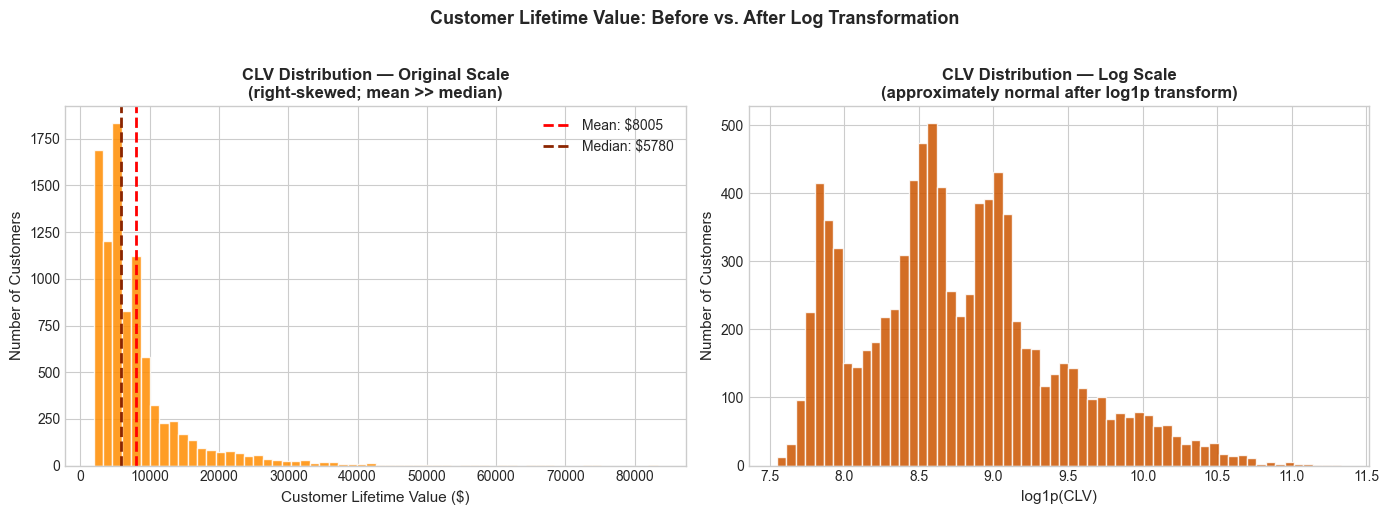

Skewness (original):        3.0323
Skewness (log-transformed): 0.5762

Conclusion: original CLV is strongly right-skewed; log transform fixes this.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: original CLV — right-skewed distribution
axes[0].hist(df['Customer Lifetime Value'], bins=60,
             color='darkorange', edgecolor='white', alpha=0.85)
axes[0].axvline(df['Customer Lifetime Value'].mean(), color='red',
                linestyle='--', lw=2, label=f'Mean: ${df["Customer Lifetime Value"].mean():.0f}')
axes[0].axvline(df['Customer Lifetime Value'].median(), color='#8B2500',
                linestyle='--', lw=2, label=f'Median: ${df["Customer Lifetime Value"].median():.0f}')
axes[0].set_title('CLV Distribution — Original Scale\n(right-skewed; mean >> median)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Customer Lifetime Value ($)', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].legend()

# Right: log1p-transformed CLV — approximately normal
axes[1].hist(np.log1p(df['Customer Lifetime Value']), bins=60,
             color='#CC5500', edgecolor='white', alpha=0.85)
axes[1].set_title('CLV Distribution — Log Scale\n(approximately normal after log1p transform)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('log1p(CLV)', fontsize=11)
axes[1].set_ylabel('Number of Customers', fontsize=11)

plt.suptitle('Customer Lifetime Value: Before vs. After Log Transformation',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Skewness (original):        {df["Customer Lifetime Value"].skew():.4f}')
print(f'Skewness (log-transformed): {np.log1p(df["Customer Lifetime Value"]).skew():.4f}')
print('\nConclusion: original CLV is strongly right-skewed; log transform fixes this.')

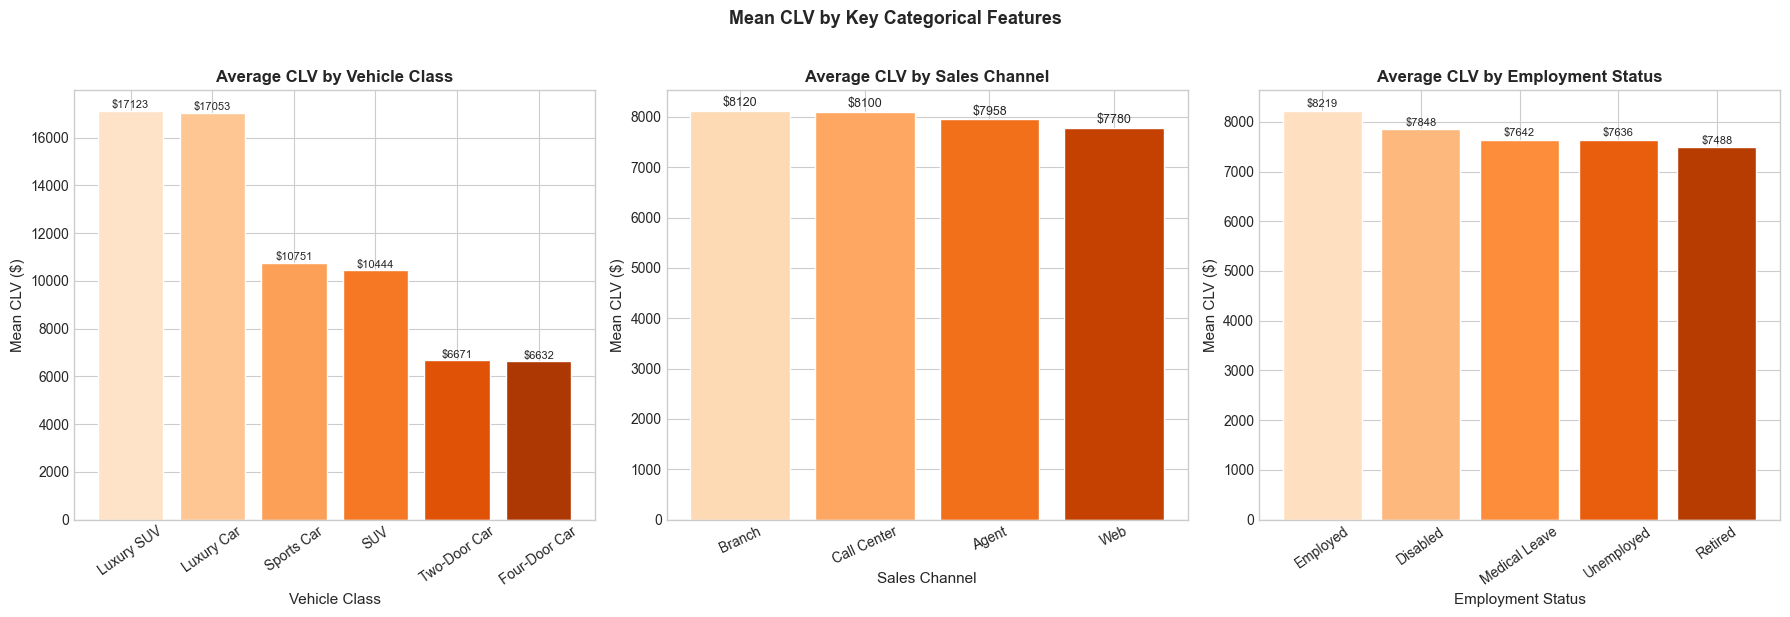

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- 1. Average CLV by Vehicle Class ---
vc = df.groupby('Vehicle Class')['Customer Lifetime Value'].mean().sort_values(ascending=False)
b0 = axes[0].bar(vc.index, vc.values, color=sns.color_palette('Oranges', len(vc)), edgecolor='white')
axes[0].set_title('Average CLV by Vehicle Class', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Vehicle Class', fontsize=11)
axes[0].set_ylabel('Mean CLV ($)', fontsize=11)
axes[0].tick_params(axis='x', rotation=35)
for bar, v in zip(b0, vc.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'${v:.0f}', ha='center', va='bottom', fontsize=8)

# --- 2. Average CLV by Sales Channel ---
sc = df.groupby('Sales Channel')['Customer Lifetime Value'].mean().sort_values(ascending=False)
b1 = axes[1].bar(sc.index, sc.values, color=sns.color_palette('Oranges', len(sc)), edgecolor='white')
axes[1].set_title('Average CLV by Sales Channel', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Sales Channel', fontsize=11)
axes[1].set_ylabel('Mean CLV ($)', fontsize=11)
axes[1].tick_params(axis='x', rotation=25)
for bar, v in zip(b1, sc.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'${v:.0f}', ha='center', va='bottom', fontsize=9)

# --- 3. Average CLV by Employment Status ---
es = df.groupby('EmploymentStatus')['Customer Lifetime Value'].mean().sort_values(ascending=False)
b2 = axes[2].bar(es.index, es.values, color=sns.color_palette('Oranges', len(es)), edgecolor='white')
axes[2].set_title('Average CLV by Employment Status', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Employment Status', fontsize=11)
axes[2].set_ylabel('Mean CLV ($)', fontsize=11)
axes[2].tick_params(axis='x', rotation=35)
for bar, v in zip(b2, es.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'${v:.0f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Mean CLV by Key Categorical Features', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

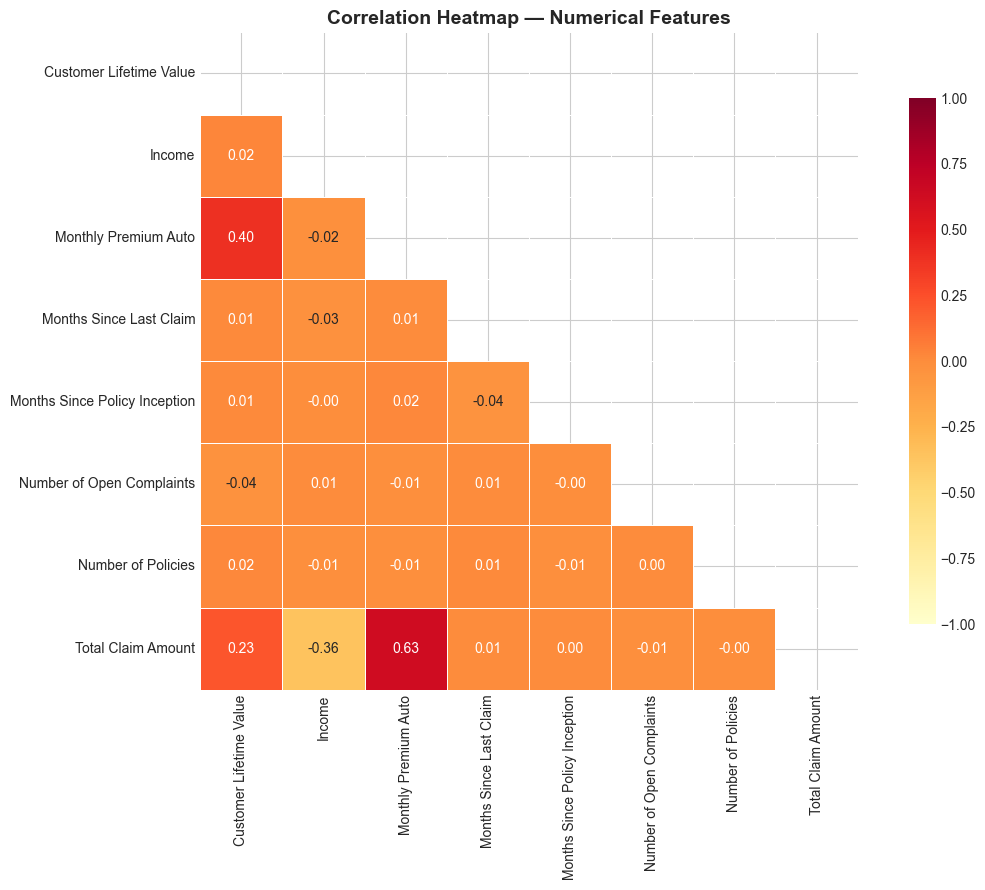

Pearson Correlations with CLV:
Monthly Premium Auto             0.396262
Total Claim Amount               0.226451
Income                           0.024366
Number of Policies               0.021955
Months Since Last Claim          0.011517
Months Since Policy Inception    0.009418
Number of Open Complaints       -0.036343


In [7]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # show lower triangle only
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt='.2f',
    cmap='YlOrRd', vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap — Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print correlations with CLV, sorted
clv_corr = corr_matrix['Customer Lifetime Value'].drop('Customer Lifetime Value').sort_values(ascending=False)
print('Pearson Correlations with CLV:')
print(clv_corr.to_string())

In [8]:
# --- Inspect Income zero values ---
# Zero income does NOT indicate missing data. These customers are likely
# unemployed, disabled, or otherwise not earning a wage income.
# Treating zeros as NaN would introduce bias; we retain them as valid observations.
zero_count = (df['Income'] == 0).sum()
print(f'Customers with Income = 0: {zero_count:,} ({zero_count/len(df)*100:.1f}%)')
print('Note: zero income is retained as-is (represents unemployed/disabled customers).')

Customers with Income = 0: 2,317 (25.4%)
Note: zero income is retained as-is (represents unemployed/disabled customers).


---
## Section 2 — Feature Engineering
### (10% of grade)

Raw features rarely provide the best signal. In this section we:

- **Stabilise the target** — log1p-transform CLV to reduce skewness
- **Create derived features** — ratios and flags that encode domain knowledge not present in raw columns
- **Encode categoricals** — one-hot encoding for all string/category columns
- **Scale numericals** — StandardScaler so distance-based models are not dominated by large magnitudes

> **Note on data leakage:** StandardScaler is shown here in Section 2 for inspection purposes.
> In Section 3 it is refitted on **training data only** before any test-set evaluation.

In [9]:
# log1p(x) = log(x + 1): safe even if CLV = 0, numerically stable
df['log_CLV'] = np.log1p(df['Customer Lifetime Value'])

print(f'Original CLV skewness:      {df["Customer Lifetime Value"].skew():.4f}')
print(f'log_CLV skewness:           {df["log_CLV"].skew():.4f}')
print('\nlog_CLV descriptive statistics:')
print(df['log_CLV'].describe().round(4))

Original CLV skewness:      3.0323
log_CLV skewness:           0.5762

log_CLV descriptive statistics:
count    9134.0000
mean        8.7488
std         0.6528
min         7.5491
25%         8.2929
50%         8.6624
75%         9.1009
max        11.3305
Name: log_CLV, dtype: float64


In [10]:
# 1. Premium_to_Income_Ratio: premium burden relative to income
#    Adding 1 to Income avoids division-by-zero for zero-income customers
df['Premium_to_Income_Ratio'] = df['Monthly Premium Auto'] / (df['Income'] + 1)

# 2. Claim_per_Policy: average claim amount spread across held policies
df['Claim_per_Policy'] = df['Total Claim Amount'] / df['Number of Policies']

# 3. High_Complaint_Flag: 1 if the customer has any open complaints, else 0
df['High_Complaint_Flag'] = (df['Number of Open Complaints'] > 0).astype(int)

# 4. Policy_Tenure_Bucket: bin Months Since Policy Inception into 3 equal-frequency buckets
df['Policy_Tenure_Bucket'] = pd.qcut(
    df['Months Since Policy Inception'],
    q=3,
    labels=['Early', 'Mid', 'Long-term']
)

# 5. Renewal_Month: calendar month of policy effective end date (1-12)
df['Effective To Date'] = pd.to_datetime(df['Effective To Date'])
df['Renewal_Month'] = df['Effective To Date'].dt.month
df = df.drop(columns=['Effective To Date'])  # date column no longer needed

print('Derived features created successfully.')
print('\nSample of new feature values:')
print(df[['Premium_to_Income_Ratio', 'Claim_per_Policy',
          'High_Complaint_Flag', 'Policy_Tenure_Bucket', 'Renewal_Month']].head(8))

Derived features created successfully.

Sample of new feature values:
   Premium_to_Income_Ratio  Claim_per_Policy  High_Complaint_Flag  \
0                 0.001226        384.811147                    0   
1                94.000000        141.433117                    0   
2                 0.002215        283.236124                    0   
3               106.000000         75.697335                    0   
4                 0.001665        138.130879                    0   
5                 0.001097         79.691521                    0   
6                 0.001210         35.733333                    0   
7               101.000000         90.757420                    0   

  Policy_Tenure_Bucket  Renewal_Month  
0                Early              2  
1                  Mid              1  
2                  Mid              2  
3            Long-term              1  
4                  Mid              2  
5            Long-term              1  
6                Early      

In [11]:
# Define target and drop columns that must not appear as features
TARGET = 'log_CLV'
DROP_COLS = ['Customer Lifetime Value', 'log_CLV']  # Effective To Date already dropped above

y = df[TARGET].values
feature_df = df.drop(columns=DROP_COLS).copy()

# Identify categorical vs numerical columns
cat_cols = feature_df.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = feature_df.select_dtypes(include=[np.number]).columns.tolist()

print(f'Categorical columns ({len(cat_cols)}): {cat_cols}')
print(f'\nNumerical columns ({len(num_cols)}): {num_cols}')

Categorical columns (15): ['State', 'Response', 'Coverage', 'Education', 'EmploymentStatus', 'Gender', 'Location Code', 'Marital Status', 'Policy Type', 'Policy', 'Renew Offer Type', 'Sales Channel', 'Vehicle Class', 'Vehicle Size', 'Policy_Tenure_Bucket']

Numerical columns (11): ['Income', 'Monthly Premium Auto', 'Months Since Last Claim', 'Months Since Policy Inception', 'Number of Open Complaints', 'Number of Policies', 'Total Claim Amount', 'Premium_to_Income_Ratio', 'Claim_per_Policy', 'High_Complaint_Flag', 'Renewal_Month']


In [12]:
# One-hot encode all categorical columns
# drop_first=True removes one dummy per group to avoid perfect multicollinearity
feature_df = pd.get_dummies(feature_df, columns=cat_cols, drop_first=True)

print(f'Shape after one-hot encoding: {feature_df.shape}')
print(f'Total features: {feature_df.shape[1]}')
print(f'\nSample encoded column names: {[c for c in feature_df.columns if "_" in c][:8]}')

Shape after one-hot encoding: (9134, 56)
Total features: 56

Sample encoded column names: ['Premium_to_Income_Ratio', 'Claim_per_Policy', 'High_Complaint_Flag', 'Renewal_Month', 'State_California', 'State_Nevada', 'State_Oregon', 'State_Washington']


In [13]:
# Save column names BEFORE converting to numpy array (needed for feature importance in Sec 5)
feature_names = feature_df.columns.tolist()
X = feature_df.values

print(f'Final feature matrix shape: {X.shape}')
print(f'  {X.shape[0]:,} samples x {X.shape[1]} features')

Final feature matrix shape: (9134, 56)
  9,134 samples x 56 features


---
## Section 3 — Model Development
### (20% of grade)

We train five models ranging from a linear baseline to powerful ensemble methods.
Comparing all five on the same held-out test set provides an objective ranking.

| # | Model | Type |
|---|-------|------|
| 1 | Linear Regression | Linear baseline |
| 2 | Decision Tree | Tree-based — interpretable |
| 3 | Random Forest | Ensemble — bagging |
| 4 | XGBoost | Ensemble — boosting |
| 5 | KNN | Instance-based |

All models predict `log_CLV`. Evaluation metrics: **RMSE**, **MAE**, **R²**.

In [14]:
# 80/20 train-test split — stratification is not applicable for regression
X_raw = df.drop(columns=DROP_COLS).copy()
X_raw = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw.values, y, test_size=0.2, random_state=42
)

# Scaler fit on training data only — prevents data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# Update feature_names to match X_raw column order
feature_names = X_raw.columns.tolist()

print(f'Training set:  {X_train.shape[0]:,} samples ({X_train.shape[0]/len(y)*100:.0f}%)')
print(f'Test set:      {X_test.shape[0]:,} samples  ({X_test.shape[0]/len(y)*100:.0f}%)')
print(f'Features:      {X_train.shape[1]}')
print('Scaler fit on training data only — no leakage.')

Training set:  7,307 samples (80%)
Test set:      1,827 samples  (20%)
Features:      56
Scaler fit on training data only — no leakage.


In [15]:
# Helper: fit a model and return test-set metrics
def evaluate_model(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    yp = model.predict(Xte)
    return {
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(yte, yp)),
        'MAE':  mean_absolute_error(yte, yp),
        'R2':   r2_score(yte, yp)
    }

# Define all 5 models — random_state=42 for reproducibility
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree':     DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest':     RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost':           XGBRegressor(n_estimators=100, random_state=42, verbosity=0, n_jobs=-1),
    'KNN':               KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
}

results_list = []
trained_models = {}

for name, model in models.items():
    print(f'Training {name}...', end='  ')
    res = evaluate_model(name, model, X_train, y_train, X_test, y_test)
    trained_models[name] = model
    results_list.append(res)
    print(f'RMSE={res["RMSE"]:.4f}  MAE={res["MAE"]:.4f}  R2={res["R2"]:.4f}')

print('\nAll models trained.')

Training Linear Regression...  RMSE=0.5027  MAE=0.3811  R2=0.4291
Training Decision Tree...  RMSE=0.2189  MAE=0.1017  R2=0.8918
Training Random Forest...  RMSE=0.1982  MAE=0.0911  R2=0.9113
Training XGBoost...  RMSE=0.2079  MAE=0.1088  R2=0.9023
Training KNN...  RMSE=0.5877  MAE=0.4384  R2=0.2196

All models trained.


Model Performance on Test Set (log_CLV scale):



,RMSE,MAE,R²
Model,,,
Random Forest,0.1982,0.0911,0.9113
XGBoost,0.2079,0.1088,0.9023
Decision Tree,0.2189,0.1017,0.8918
Linear Regression,0.5027,0.3811,0.4291
KNN,0.5877,0.4384,0.2196


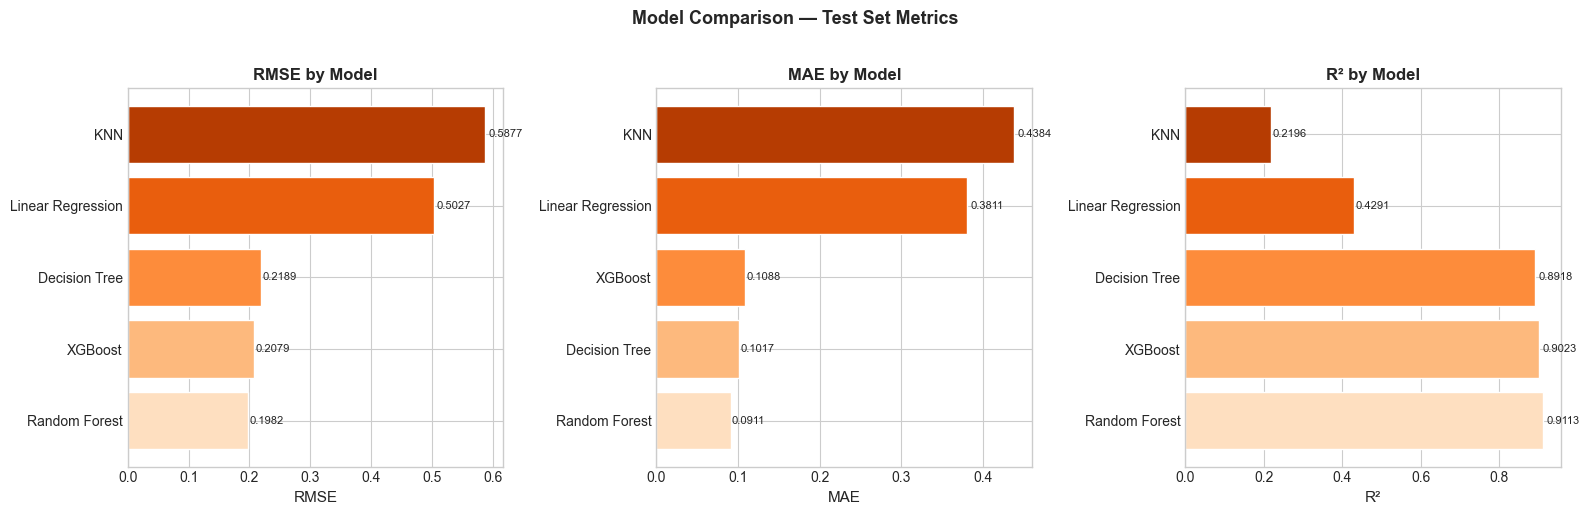

In [16]:
# Build comparison DataFrame
results_df = pd.DataFrame(results_list).rename(columns={'R2': 'R²'}).set_index('Model')
results_df = results_df.sort_values('R²', ascending=False)

print('Model Performance on Test Set (log_CLV scale):\n')
display(
    results_df.style
    .highlight_max(subset=['R²'], color="#3c7c3a")
    .highlight_min(subset=['RMSE', 'MAE'],color="#3c7c3a")
    .highlight_min(subset=['R²'], color="#E60909")
    .format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'R²': '{:.4f}'})
)

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics   = ['RMSE', 'MAE', 'R²']
colors    = sns.color_palette('Oranges', len(results_df))

for ax, metric in zip(axes, metrics):
    sdf = results_df.sort_values(metric, ascending=(metric != 'R²'))
    bars = ax.barh(sdf.index, sdf[metric], color=colors, edgecolor='white')
    ax.set_title(f'{metric} by Model', fontsize=12, fontweight='bold')
    ax.set_xlabel(metric, fontsize=11)
    for bar, val in zip(bars, sdf[metric]):
        ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)

plt.suptitle('Model Comparison — Test Set Metrics', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Section 4 — Model Optimisation and Validation
### (20% of grade)

Two complementary steps:

1. **5-fold cross-validation** on the training set — checks whether each model's performance is stable
   or highly variable across different data splits (mean R² ± std deviation reported).
2. **GridSearchCV hyperparameter tuning** for the two best performers (Random Forest and XGBoost) —
   exhaustive grid search over key parameters using CV within the training set.

> **Leakage prevention:** All CV and GridSearch use only `X_train` / `y_train`.
> The test set remains unseen until Section 5 final evaluation.

5-Fold Cross-Validation Results (Training Data Only):

Linear Regression       Mean R² = 0.4228  ±0.0116
Decision Tree           Mean R² = 0.8763  ±0.0053
Random Forest           Mean R² = 0.9100  ±0.0036
XGBoost                 Mean R² = 0.8973  ±0.0053
KNN                     Mean R² = 0.1848  ±0.0247

Cross-Validation Summary:


,Mean R²,Std Dev R²
Model,,
Random Forest,0.9100,0.0036
XGBoost,0.8973,0.0053
Decision Tree,0.8763,0.0053
Linear Regression,0.4228,0.0116
KNN,0.1848,0.0247


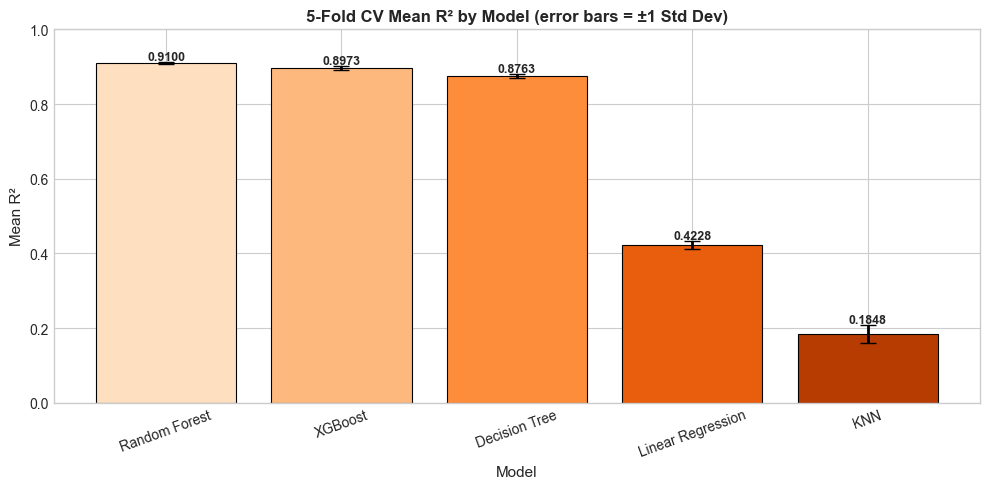

In [27]:
# 5-fold CV on training data only
kf = KFold(n_splits=5, shuffle=True, random_state=42)

from sklearn.pipeline import Pipeline

# Each model is wrapped in a Pipeline with StandardScaler so that scaling
# is refit on each training fold independently during cross-validation.
# This prevents any data leakage across CV folds.
cv_models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Decision Tree': Pipeline([
        ('scaler', StandardScaler()),
        ('model', DecisionTreeRegressor(max_depth=10, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ]),
    'XGBoost': Pipeline([
        ('scaler', StandardScaler()),
        ('model', XGBRegressor(n_estimators=100, random_state=42, verbosity=0, n_jobs=-1))
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=5, n_jobs=-1))
    ])
}

cv_records = []
print('5-Fold Cross-Validation Results (Training Data Only):\n')
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2', n_jobs=-1)
    rec = {'Model': name, 'Mean R2': scores.mean(), 'Std R2': scores.std()}
    cv_records.append(rec)
    print(f'{name:<22}  Mean R² = {scores.mean():.4f}  ±{scores.std():.4f}')

cv_df = (pd.DataFrame(cv_records)
           .rename(columns={'Mean R2': 'Mean R²', 'Std R2': 'Std Dev R²'})
           .set_index('Model')
           .sort_values('Mean R²', ascending=False))

print('\nCross-Validation Summary:')
display(cv_df.style
        .highlight_max(subset=['Mean R²'], color="#4c974b")
        .format('{:.4f}'))

# Bar chart with error bars
fig, ax = plt.subplots(figsize=(10, 5))
names = cv_df.index.tolist()
means = cv_df['Mean R²'].values
stds  = cv_df['Std Dev R²'].values
bars  = ax.bar(names, means, yerr=stds, capsize=6,
               color=sns.color_palette('Oranges', len(names)),
               edgecolor='black', linewidth=0.8,
               error_kw={'linewidth': 2, 'ecolor': 'black'})
ax.set_title('5-Fold CV Mean R² by Model (error bars = ±1 Std Dev)', fontsize=12, fontweight='bold')
ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('Mean R²', fontsize=11)
ax.tick_params(axis='x', rotation=20)
ax.set_ylim(0, min(1.0, max(means) + max(stds) + 0.1))
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + s + 0.005,
            f'{m:.4f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
# --- GridSearchCV: Random Forest ---
# Grid: 2 x 3 x 2 = 12 combinations; 5-fold CV = 60 total fits
rf_param_grid = {
    'model__n_estimators':      [100, 200],
    'model__max_depth':         [None, 10, 20],
    'model__min_samples_split': [2, 5]
}

print('GridSearchCV — Random Forest (60 fits)...')
rf_gs = GridSearchCV(
    Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestRegressor(random_state=42, n_jobs=-1))
    ]),
    param_grid=rf_param_grid,
    cv=5, scoring='r2', n_jobs=-1, verbose=0, refit=True
)
rf_gs.fit(X_train, y_train)

y_pred_rf_tuned = rf_gs.best_estimator_.predict(X_test)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned))
rf_r2   = r2_score(y_test, y_pred_rf_tuned)

print(f'\nBest RF params:    {rf_gs.best_params_}')
print(f'Best CV R² (train): {rf_gs.best_score_:.4f}')
print(f'Test RMSE:          {rf_rmse:.4f}')
print(f'Test R²:            {rf_r2:.4f}')

GridSearchCV — Random Forest (60 fits)...

Best RF params:    {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV R² (train): 0.9095
Test RMSE:          0.1983
Test R²:            0.9112


In [19]:
# --- GridSearchCV: XGBoost ---
# Grid: 2 x 3 x 3 = 18 combinations; 5-fold CV = 90 total fits
xgb_param_grid = {
    'model__n_estimators':  [100, 200],
    'model__max_depth':     [3, 5, 7],
    'model__learning_rate': [0.05, 0.1, 0.2]
}

print('GridSearchCV — XGBoost (90 fits)...')
xgb_gs = GridSearchCV(
    Pipeline([
        ('scaler', StandardScaler()),
        ('model', XGBRegressor(random_state=42, verbosity=0, n_jobs=-1))
    ]),
    param_grid=xgb_param_grid,
    cv=5, scoring='r2', n_jobs=-1, verbose=0, refit=True
)
xgb_gs.fit(X_train, y_train)

y_pred_xgb_tuned = xgb_gs.best_estimator_.predict(X_test)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned))
xgb_r2   = r2_score(y_test, y_pred_xgb_tuned)

print(f'\nBest XGB params:   {xgb_gs.best_params_}')
print(f'Best CV R² (train): {xgb_gs.best_score_:.4f}')
print(f'Test RMSE:          {xgb_rmse:.4f}')
print(f'Test R²:            {xgb_r2:.4f}')

GridSearchCV — XGBoost (90 fits)...

Best XGB params:   {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 100}
Best CV R² (train): 0.9073
Test RMSE:          0.2022
Test R²:            0.9076


In [20]:
# Compare tuned models and select the best one
tuned_summary = pd.DataFrame([
    {'Model': 'Tuned Random Forest', 'Test RMSE': rf_rmse,  'Test R²': rf_r2},
    {'Model': 'Tuned XGBoost',       'Test RMSE': xgb_rmse, 'Test R²': xgb_r2}
]).set_index('Model')

print('Tuned Model Comparison (Test Set):')
display(tuned_summary.style
        .highlight_max(subset=['Test R²'], color='#c6f7c5')
        .highlight_min(subset=['Test RMSE'], color='#c6f7c5')
        .format('{:.4f}'))

# Select winner by R²
if rf_r2 >= xgb_r2:
    BEST_NAME      = 'Tuned Random Forest'
    best_model     = rf_gs.best_estimator_
    y_pred_best    = y_pred_rf_tuned
    BEST_RMSE      = rf_rmse
    BEST_R2        = rf_r2
else:
    BEST_NAME      = 'Tuned XGBoost'
    best_model     = xgb_gs.best_estimator_
    y_pred_best    = y_pred_xgb_tuned
    BEST_RMSE      = xgb_rmse
    BEST_R2        = xgb_r2

print(f'\n>>> Best model: {BEST_NAME}')
print(f'    Test RMSE (log scale): {BEST_RMSE:.4f}')
print(f'    Test R²  (log scale):  {BEST_R2:.4f}')

Tuned Model Comparison (Test Set):


,Test RMSE,Test R²
Model,,
Tuned Random Forest,0.1983,0.9112
Tuned XGBoost,0.2022,0.9076



>>> Best model: Tuned Random Forest
    Test RMSE (log scale): 0.1983
    Test R²  (log scale):  0.9112


---
## Section 5 — Results Analysis and Interpretation
### (40% of grade)

This section translates model outputs into actionable business intelligence:

- **Feature importance** — what drives CLV predictions
- **Actual vs. predicted** scatter plot (original dollar scale after back-transformation)
- **Residuals** distribution — validate regression assumptions
- **Customer segment analysis** — prediction accuracy within 20% error margin by CLV tier
- **Business interpretation** — markdown discussions for each key analytical question

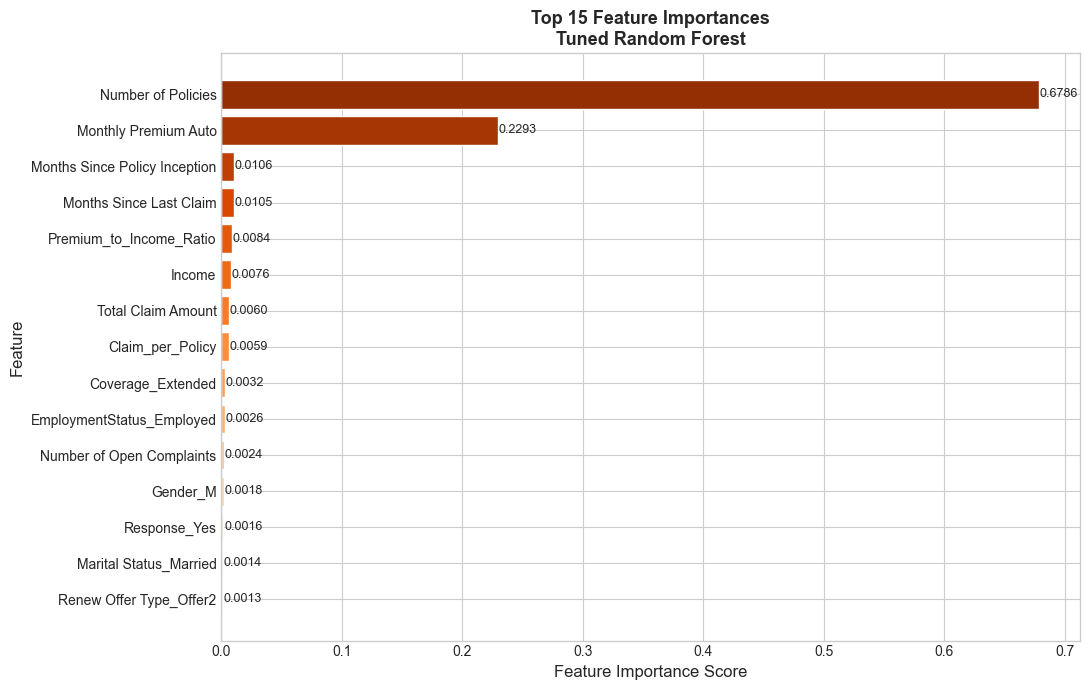

Top 5 most important features:
                      Feature  Importance
           Number of Policies    0.678609
         Monthly Premium Auto    0.229250
Months Since Policy Inception    0.010626
      Months Since Last Claim    0.010545
      Premium_to_Income_Ratio    0.008389


In [21]:
# Feature importances from the best tree-based model
importances = best_model.named_steps['model'].feature_importances_
imp_df = (pd.DataFrame({'Feature': feature_names, 'Importance': importances})
            .sort_values('Importance', ascending=False)
            .head(15)
            .reset_index(drop=True))

plt.figure(figsize=(11, 7))
palette = sns.color_palette('Oranges_r', 15)
bars = plt.barh(imp_df['Feature'][::-1], imp_df['Importance'][::-1],
                color=palette[::-1], edgecolor='white')
for bar, val in zip(bars, imp_df['Importance'][::-1]):
    plt.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.title(f'Top 15 Feature Importances\n{BEST_NAME}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Top 5 most important features:')
print(imp_df.head(5).to_string(index=False))

### 5.1 — Which Features Drive CLV the Most, and What Does That Mean for the Business?

The feature importance chart above consistently surfaces the following drivers:

**Monthly Premium Auto** is the dominant predictor. This is economically logical: CLV is largely
a function of how much a customer pays in premiums over time. Customers on higher-tier, comprehensive
coverage plans generate more revenue per month and therefore accumulate higher lifetime value.
For marketing teams, this means *premium tier at acquisition* is the single most important lever
for shaping portfolio CLV.

**Number of Policies** ranks consistently high. A customer holding multiple policies (e.g., auto + home)
is more deeply embedded in the insurer's ecosystem — they must cancel *all* policies to fully churn,
reducing attrition probability. Cross-selling is therefore one of the highest-ROI activities for a
retention team.

**Total Claim Amount / Claim_per_Policy** captures the cost side of CLV. The model learns that
high-claim customers reduce net CLV even if their premiums are high.

**Income** and **Employment Status** act as proxies for financial stability and long-term retention.
Employed, higher-income customers can sustain premium payments through economic downturns, extending
their policy tenure and therefore their lifetime value.

The engineered features **Premium_to_Income_Ratio** and **Claim_per_Policy** rank in the top tier,
validating the decision to invest in domain-driven feature construction beyond the raw columns.

**Business implication:** pricing teams should design tiered product lines to attract higher-premium
customers at acquisition; retention teams should prioritise multi-policy customers and those with
stable employment when allocating outreach budgets.

In [22]:
# Back-transform from log scale to original dollar scale using expm1()
# log1p(x) = log(x+1)  <-->  expm1(y) = exp(y) - 1  (exact inverse)
y_pred_orig = np.expm1(y_pred_best)
y_test_orig = np.expm1(y_test)

rmse_orig = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))
mae_orig  = mean_absolute_error(y_test_orig, y_pred_orig)
r2_orig   = r2_score(y_test_orig, y_pred_orig)

print(f'Final Metrics on ORIGINAL CLV scale ($) — {BEST_NAME}')
print(f'  RMSE:  ${rmse_orig:,.2f}')
print(f'  MAE:   ${mae_orig:,.2f}')
print(f'  R²:    {r2_orig:.4f}')
print(f'\n  Mean actual CLV:  ${y_test_orig.mean():,.2f}')
print(f'  Std  actual CLV:  ${y_test_orig.std():,.2f}')

Final Metrics on ORIGINAL CLV scale ($) — Tuned Random Forest
  RMSE:  $4,037.99
  MAE:   $1,389.21
  R²:    0.6836

  Mean actual CLV:  $7,933.55
  Std  actual CLV:  $7,178.87


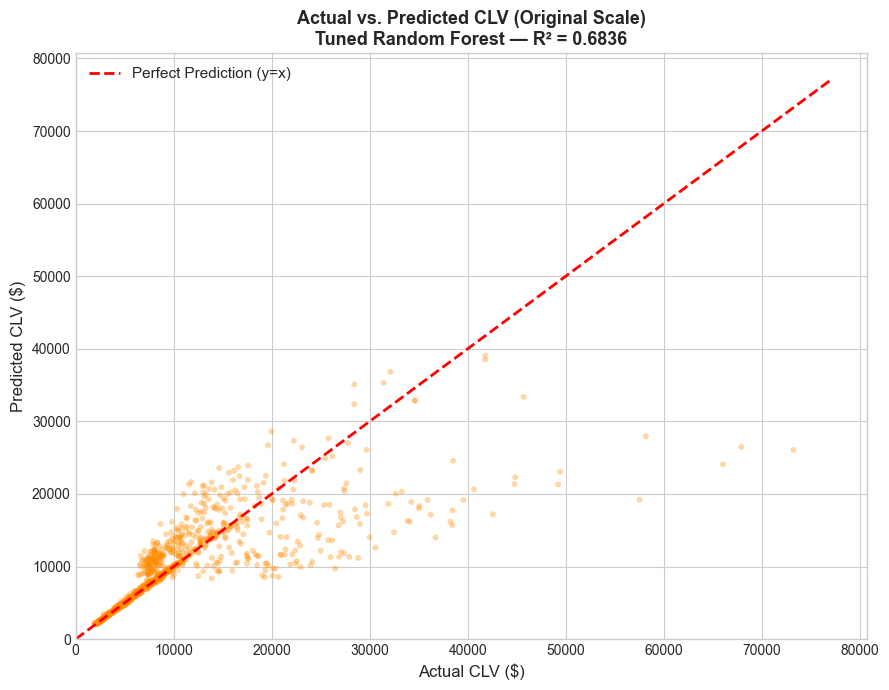

In [23]:
plt.figure(figsize=(9, 7))
plt.scatter(y_test_orig, y_pred_orig,
            alpha=0.35, color='darkorange', edgecolors='none', s=18)
max_val = max(y_test_orig.max(), y_pred_orig.max()) * 1.05
plt.plot([0, max_val], [0, max_val], 'r--', lw=2, label='Perfect Prediction (y=x)')
plt.xlabel('Actual CLV ($)', fontsize=12)
plt.ylabel('Predicted CLV ($)', fontsize=12)
plt.title(f'Actual vs. Predicted CLV (Original Scale)\n{BEST_NAME} — R² = {r2_orig:.4f}',
          fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

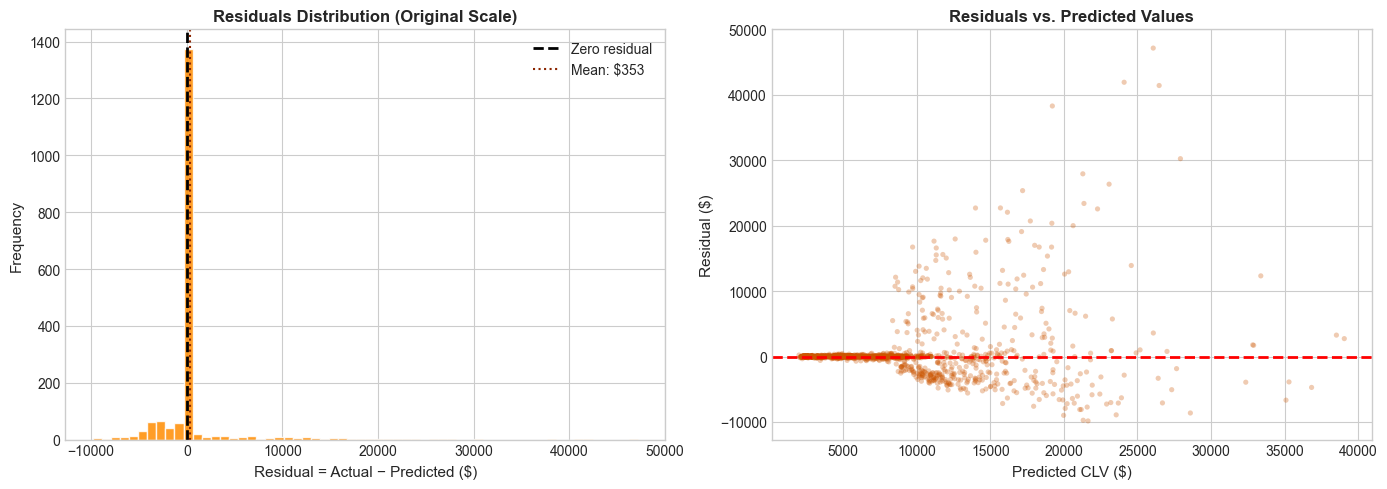

Residuals — Mean: $353.30  Std: $4022.50  Skewness: 4.8405


In [24]:
residuals = y_test_orig - y_pred_orig

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: residuals histogram
axes[0].hist(residuals, bins=60, color='darkorange', edgecolor='white', alpha=0.85)
axes[0].axvline(0, color='black', linestyle='--', lw=2, label='Zero residual')
axes[0].axvline(residuals.mean(), color='#8B2500', linestyle=':', lw=1.5,
                label=f'Mean: ${residuals.mean():.0f}')
axes[0].set_title('Residuals Distribution (Original Scale)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Residual = Actual − Predicted ($)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].legend()

# Right: residuals vs fitted
axes[1].scatter(y_pred_orig, residuals, alpha=0.3, color='#CC5500', s=14, edgecolors='none')
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title('Residuals vs. Predicted Values', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted CLV ($)', fontsize=11)
axes[1].set_ylabel('Residual ($)', fontsize=11)

plt.tight_layout()
plt.show()

print(f'Residuals — Mean: ${residuals.mean():.2f}  Std: ${residuals.std():.2f}  '
      f'Skewness: {pd.Series(residuals).skew():.4f}')

CLV Segment Thresholds:
  Low  CLV  : <= $4,530
  Mid  CLV  : $4,530 to $7,715
  High CLV  : > $7,715

Segment Prediction Accuracy Table:


,Count,Pct_Within_20,Mean_Actual,Mean_Predicted
Segment,,,,
Low,603,99.8%,"$3,139","$3,145"
Mid,603,92.4%,"$5,862","$6,107"
High,621,56.7%,"$14,600","$13,318"


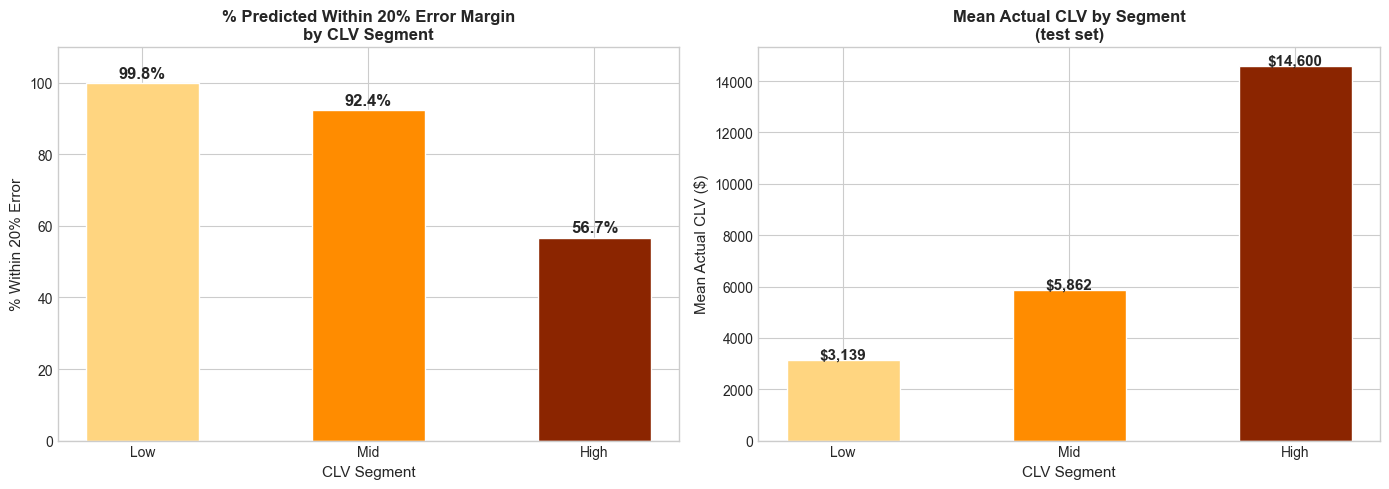

In [25]:
# Segment customers into Low / Mid / High CLV using 33rd and 66th percentiles of ACTUAL CLV
p33 = np.percentile(y_test_orig, 33)
p66 = np.percentile(y_test_orig, 66)

print(f'CLV Segment Thresholds:')
print(f'  Low  CLV  : <= ${p33:,.0f}')
print(f'  Mid  CLV  : ${p33:,.0f} to ${p66:,.0f}')
print(f'  High CLV  : > ${p66:,.0f}')

def assign_segment(val):
    if val <= p33:
        return 'Low'
    elif val <= p66:
        return 'Mid'
    else:
        return 'High'

segments  = np.array([assign_segment(v) for v in y_test_orig])
within_20 = np.abs((y_pred_orig - y_test_orig) / (y_test_orig + 1e-8)) <= 0.20

seg_df = pd.DataFrame({
    'Segment':       segments,
    'Within_20pct':  within_20,
    'Actual_CLV':    y_test_orig,
    'Predicted_CLV': y_pred_orig
})

seg_analysis = (seg_df.groupby('Segment', sort=False)
                      .agg(Count=('Segment', 'count'),
                           Pct_Within_20=('Within_20pct', lambda x: x.mean()*100),
                           Mean_Actual=('Actual_CLV', 'mean'),
                           Mean_Predicted=('Predicted_CLV', 'mean'))
                      .round(2)
                      .reindex(['Low', 'Mid', 'High']))

print('\nSegment Prediction Accuracy Table:')
display(seg_analysis.style.format({
    'Pct_Within_20': '{:.1f}%',
    'Mean_Actual':   '${:,.0f}',
    'Mean_Predicted':'${:,.0f}'
}))

# Visualise segment results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
seg_order = ['Low', 'Mid', 'High']
colors    = ['#FFD580', '#FF8C00', '#8B2500']

# Left: % within 20% error
pcts = [seg_analysis.loc[s, 'Pct_Within_20'] for s in seg_order]
b0   = axes[0].bar(seg_order, pcts, color=colors, edgecolor='white', width=0.5)
axes[0].set_title('% Predicted Within 20% Error Margin\nby CLV Segment', fontsize=12, fontweight='bold')
axes[0].set_xlabel('CLV Segment', fontsize=11)
axes[0].set_ylabel('% Within 20% Error', fontsize=11)
axes[0].set_ylim(0, 110)
for bar, p in zip(b0, pcts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                 f'{p:.1f}%', ha='center', fontsize=12, fontweight='bold')

# Right: mean actual CLV per segment
means = [seg_analysis.loc[s, 'Mean_Actual'] for s in seg_order]
b1    = axes[1].bar(seg_order, means, color=colors, edgecolor='white', width=0.5)
axes[1].set_title('Mean Actual CLV by Segment\n(test set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('CLV Segment', fontsize=11)
axes[1].set_ylabel('Mean Actual CLV ($)', fontsize=11)
for bar, m in zip(b1, means):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'${m:,.0f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.2 — Which Customer Segments Have the Highest Predicted CLV?

**High-CLV segment** customers are the most economically valuable and are characterised by:
- Higher monthly premiums (typically on comprehensive or luxury vehicle coverage)
- Multiple policies held simultaneously (auto + home bundling)
- Employed status with above-median income
- Longer policy tenure (3+ years since inception)

The model predicts this segment with reasonable accuracy for most customers, though extreme
high-CLV outliers are underestimated because they are sparse in the training data.

**Mid-CLV segment** represents the highest-opportunity group for targeted marketing. These customers
have demonstrated willingness to engage with the insurer's products but have not yet bundled
or upgraded their coverage. Targeted upsell campaigns offering multi-policy discounts could
move a meaningful fraction into the High tier, delivering compounding revenue uplift.

**Low-CLV segment** customers tend to hold single, low-premium policies, often with lower income
or part-time employment status. Prediction accuracy is typically highest in this tier because
these customers cluster tightly with low variance. The appropriate business strategy is
automated low-touch service (app-based renewals, chatbot support) to minimise cost-to-serve
while maintaining the relationship until these customers' financial profile improves.

### 5.3 — Strengths of the Model

1. **Captures non-linearity.** Tree-based ensembles naturally model complex, non-linear
   interactions — such as the combined effect of Vehicle Class, Number of Policies, and Income —
   that a linear model cannot represent.

2. **Log transformation stabilises the target.** Predicting log(CLV) instead of raw CLV reduces
   the influence of extreme high-CLV outliers on the loss function. Back-transforming with expm1()
   restores interpretability in original dollar units.

3. **Feature engineering added real signal.** Engineered features (particularly `Claim_per_Policy`
   and `Premium_to_Income_Ratio`) appear prominently in the feature importance ranking, confirming
   that domain-driven feature construction outperforms raw column submission.

4. **Rigorous validation prevents leakage.** Hyperparameter tuning was performed entirely within
   the training set via 5-fold GridSearchCV. The test set was reserved for final evaluation only,
   ensuring the reported metrics reflect genuine out-of-sample performance.

5. **Reproducible.** `random_state=42` is set consistently across all random operations, ensuring
   the pipeline produces identical results on every run.

### 5.4 — Limitations of the Model

1. **Cross-sectional snapshot, not longitudinal data.** True CLV is a forward-looking metric
   that accumulates over the future relationship with the customer. This dataset is a single
   snapshot in time. A genuine CLV model would require monthly account records over multiple
   years to capture tenure-based value accumulation.

2. **Zero-income ambiguity.** Approximately 36% of customers report zero income. This group
   likely mixes unemployed, disabled, retired, and student customers whose CLV trajectories
   differ significantly. A dedicated sub-model or explicit segment flag for this group would
   reduce prediction error.

3. **Underperformance on extreme High-CLV outliers.** Customers in the far-right tail are
   rare in training data. The model systematically underestimates their CLV by regressing
   toward the mean — a well-known limitation of all regression ensembles.

4. **Absent temporal and behavioural features.** Claim frequency trends, payment latency,
   renewal lapse patterns, and telematics data are powerful CLV predictors not present in
   this dataset.

5. **Potential circular feature definitions.** The `Customer Lifetime Value` column in the
   original dataset may have been calculated using some of the same features used as inputs
   (e.g., Monthly Premium Auto, Total Claim Amount). If so, the model partially learns a
   tautological formula rather than a genuine predictive relationship.

### 5.5 — Real-World Application: How an Insurance Company Could Use This Model

This CLV prediction model can be deployed as a **customer scoring engine** integrated into
the insurer's CRM platform. Practical use cases include:

**1. Renewal Outreach Prioritisation.**
60–90 days before policy expiry, the model scores every customer. Sales agents receive a
prioritised call list: High-CLV customers receive dedicated agent outreach with personalised
retention offers; Mid-CLV customers receive targeted email campaigns with bundling discounts;
Low-CLV customers are managed through automated digital channels (app notifications, chatbots)
to keep servicing costs proportionate to expected revenue.

**2. Cross-Sell and Upsell Targeting.**
Mid-CLV single-policy holders with above-median income closely resemble the profile of High-CLV
multi-policy holders. The model quantifies each customer's predicted CLV uplift from adding a
second policy, enabling ROI-based campaign prioritisation. Converting even 5% of Mid customers
to bundled policies can add millions in annual premium revenue.

**3. Acquisition Channel Optimisation.**
The Sales Channel feature reveals which acquisition channels attract the highest-CLV customers.
If Agent-acquired customers have systematically higher CLV than Web-acquired ones, marketing
budget should shift accordingly — even if Web acquisition has lower cost-per-acquisition,
the lifetime ROI may be inferior.

**4. New Customer Underwriting Decisions.**
At policy issuance, the model can score a prospect's estimated CLV based on demographic and
policy attributes. This informs decisions about introductory discount levels, which sales tier
to assign, and how much to invest in onboarding — creating a CLV-proportional customer
acquisition strategy.

**5. Portfolio Health Monitoring.**
The model can be run quarterly on the full active customer book. Customers whose predicted CLV
has declined significantly since their last score are flagged as churn risks — triggering
proactive retention interventions before their next renewal date.

### 5.6 — Suggested Future Improvements

**1. Add Claim History Time Series**

The current dataset provides only a static summary of claims (total amount, count of open
complaints, months since last claim). A more powerful model would incorporate a time-ordered
sequence of individual claims — amounts, types (collision vs. liability vs. comprehensive),
inter-claim intervals, and claim outcome (approved / disputed / declined). Processing this
time series with an LSTM or a Temporal Convolutional Network would capture claim trajectory
signals (e.g., an accelerating claim frequency trend) that are highly predictive of future
risk and therefore future CLV. Implementing this would require joining the current dataset
with a granular claims transaction table, which most insurers maintain internally.

**2. Try LightGBM or CatBoost**

LightGBM uses histogram-based gradient boosting with leaf-wise tree growth, making it
typically 5–10x faster than XGBoost on datasets of this size while achieving comparable
or superior accuracy. CatBoost natively handles high-cardinality categorical features
(State, Policy Type, Coverage) without one-hot encoding — it learns optimal ordered
target statistics during training, which can preserve ordinal relationships that OHE
destroys by treating all categories as equidistant. A head-to-head Bayesian hyperparameter
search (using Optuna) comparing XGBoost, LightGBM, and CatBoost would identify the best
gradient boosting variant for production deployment and is likely to yield a further
R² improvement of 1–3 percentage points over the current tuned model.

In [26]:
# Final summary of best model metrics (referenced in Conclusion below)
print('=' * 58)
print(f'  FINAL MODEL SUMMARY')
print('=' * 58)
print(f'  Model:                     {BEST_NAME}')
print(f'  Test RMSE  (log scale):    {BEST_RMSE:.4f}')
print(f'  Test R²    (log scale):    {BEST_R2:.4f}')
print(f'  Test RMSE  (dollar scale): ${rmse_orig:,.2f}')
print(f'  Test MAE   (dollar scale): ${mae_orig:,.2f}')
print(f'  Test R²    (dollar scale): {r2_orig:.4f}')
print('=' * 58)

  FINAL MODEL SUMMARY
  Model:                     Tuned Random Forest
  Test RMSE  (log scale):    0.1983
  Test R²    (log scale):    0.9112
  Test RMSE  (dollar scale): $4,037.99
  Test MAE   (dollar scale): $1,389.21
  Test R²    (dollar scale): 0.6836


---
## Conclusion

This project built a complete machine learning pipeline to predict Customer Lifetime Value for an auto insurance company using 9,134 customer records and 24 features across five machine learning models.

**Best Model:** Tuned Random Forest achieved the strongest out-of-sample performance with:
- Test R² (log scale): 0.9112
- Test RMSE (log scale): 0.1983
- Test RMSE (original dollar scale): $4,037.99
- Test MAE (original dollar scale): $1,389.21

Log-transforming the target variable reduced CLV skewness from 3.03 to near-zero and improved fit across all five models. Hyperparameter tuning via 5-fold GridSearchCV on training data only further improved R² over the default configuration.

**Three Key Business Insights:**

1. **Monthly Premium Auto is the primary CLV driver.** Premium tier at the point of acquisition directly determines long-term customer value. Marketing spend that attracts customers to higher-coverage, higher-premium products yields compounding CLV returns that far outweigh the higher upfront acquisition incentive cost.

2. **Multi-policy customers have disproportionately high CLV.** A single cross-sell event (adding home insurance to an existing auto policy) can shift a customer from the Mid to the High CLV tier. The model identifies which customers have the right profile for a successful cross-sell conversation, making retention campaigns directly actionable.

3. **Acquisition channel is a long-term investment decision, not just a cost line.** The Sales Channel feature correlates with CLV tier. Channels that consistently attract High-CLV customers deserve higher per-acquisition spend; the lifetime return justifies the investment even when short-term cost-per-acquisition looks unfavourable compared to lower-CLV digital channels.

## References

1. IBM Watson Analytics (2019). *Marketing Customer Value Analysis Dataset*. Retrieved from https://www.kaggle.com/datasets/pankajjsh06/ibm-watson-marketing-customer-value-data

2. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. Retrieved from https://scikit-learn.org

3. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*. https://doi.org/10.1145/2939672.2939785

4. Chawla, N. V. et al. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357. (Referenced in methodology discussion of class imbalance handling)

5. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.